<a href="https://colab.research.google.com/github/s25omar7-ui/used-cars-price-prediction/blob/main/Copy_of_used_cars_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# توقع أسعار السيارات المستعملة في السعودية (كيا)

## 1. المشكلة
توقع سعر سيارة كيا مستعملة بالريال السعودي من مواصفاتها (الموديل، السنة، الممشى...).

## 2. من المستفيد؟
البائع الذي يريد تسعير سيارته، والمشتري الذي يريد معرفة هل السعر عادل.

## 3. نوع المشكلة
انحدار (Regression)، لأن الهدف رقم مستمر (السعر).

## 4. النطاق والافتراضات (تم التحديث بعد فحص البيانات)
- الماركة: كيا فقط (عدد الصفوف: **96**)
- سنوات الصنع: 2015–2020
- الممشى: 100 ألف – 500 ألف كم

## 5. مقاييس النجاح
- MAE: متوسط الخطأ بالريال.
- MAPE: متوسط الخطأ النسبي.
- R²: نسبة التباين التي يفسرها النموذج.
- **Baseline:** توقع متوسط السعر لكل موديل (MAE: 5,997.33 ريال، MAPE: 44.04%).
- **الهدف:** خفض MAE بنسبة **30%** عن الـ Baseline (ليصبح أقل من 4,200 ريال تقريباً).

## 6. حدود المشروع
- الأسعار المعروضة في الإعلانات قد تختلف عن أسعار البيع النهائية.
- البيانات لا تتضمن حالة السيارة (حوادث، صيانة).

# الأسبوع 1: تعريف المشكلة وفحص البيانات

In [4]:
import pandas as pd

# قراءة الملف النظيف المتاح في البيئة الخاصة بك
df = pd.read_csv('/content/d1.csv')

# تصفية البيانات لسيارات كيا (2015-2020) والممشى (100k - 500k)
kia_df = df[
    (df['Make'].str.lower() == 'kia') &
    (df['Year'].between(2015, 2020)) &
    (df['Mileage'].between(100000, 500000)) &
    (df['Price'] > 0)
].copy()

# 1. عدد الصفوف
print(f"عدد صفوف كيا بعد التصفية: {len(kia_df)}")

# 2. حساب الـ Baseline (متوسط السعر لكل موديل)
baseline_preds = kia_df.groupby('Type')['Price'].transform('mean')

# 3. حساب المقاييس للـ Baseline
mae_baseline = (kia_df['Price'] - baseline_preds).abs().mean()
mape_baseline = ((kia_df['Price'] - baseline_preds).abs() / kia_df['Price']).mean() * 100

print(f"Baseline MAE: {mae_baseline:.2f} ريال")
print(f"Baseline MAPE: {mape_baseline:.2f}%")

عدد صفوف كيا بعد التصفية: 96
Baseline MAE: 5997.33 ريال
Baseline MAPE: 44.04%


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# الأسبوع 2: التنظيف والـ Baseline

In [5]:
# فحص الاسعار

print(kia_df['Price'].describe())
cols = ['Type', 'Year', 'Mileage', 'Price']
print(kia_df.sort_values('Price').head(10)[cols])
print(kia_df.sort_values('Price').tail(10)[cols])

count       96.000000
mean     39836.927083
std      15446.394953
min       1345.000000
25%      27375.000000
50%      37000.000000
75%      51625.000000
max      73000.000000
Name: Price, dtype: float64
         Type  Year  Mileage  Price
4276   Optima  2018   135000   1345
102   Picanto  2015   133000  18500
3406  Picanto  2015   142000  18500
246   Picanto  2015   136000  18500
4222      Rio  2016   119000  20000
2910  Picanto  2017   148000  20000
984       Rio  2016   188000  21000
1817      Rio  2016   237000  21000
2103      Rio  2015   182000  21000
2548  Picanto  2017   141000  22500
          Type  Year  Mileage  Price
198    Cadenza  2016   145000  63000
2042   Cadenza  2018   148884  65000
6794    Sedona  2016   118000  65000
550   Sportage  2017   125000  65000
746    Cadenza  2018   172000  68000
6586    Optima  2016   161000  68000
1411  Carnival  2018   100000  69000
3420  Carnival  2016   120000  70000
2043   Cadenza  2018   155652  72500
132    Cadenza  2017   179000 

In [6]:
#الـ Baseline (أبسط تخمين)

def loo_baseline(d, col):
    gmean = d['Price'].mean()
    preds = []
    for i, row in d.iterrows():
        others = d[(d[col] == row[col]) & (d.index != i)]['Price']
        preds.append(others.mean() if len(others) else gmean)
    return pd.Series(preds, index=d.index)

# تم تعديل 'Type_grouped' إلى 'Type' لحل مشكلة KeyError
base = loo_baseline(kia_df, 'Type')
mae = (kia_df['Price'] - base).abs().mean()
mape = ((kia_df['Price'] - base).abs() / kia_df['Price']).mean() * 100

print(f"Baseline MAE: {mae:.0f} ريال | MAPE: {mape:.1f}%")
print(f"هدفي: MAE أقل من {mae*0.7:.0f} ريال")

Baseline MAE: 6840 ريال | MAPE: 47.2%
هدفي: MAE أقل من 4788 ريال


In [7]:
before = len(kia_df)
kia_df = kia_df[kia_df['Price'] >= 5000].copy()

print("حذفنا:", before - len(kia_df), "| بقي:", len(kia_df))
print("أقل سعر الآن:", kia_df['Price'].min())

حذفنا: 1 | بقي: 95
أقل سعر الآن: 18500


In [8]:
#حفظ البيانات النظيفة


kia_df.to_csv('kia_clean.csv', index=False)

from google.colab import files
files.download('kia_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

كم سيارة صارت عندي بعد التنظيف؟

233 سيارة
------------------------------------
ما رقم الـ Baseline، وما هدفي؟

Baseline MAE: 10839 ريال | MAPE: 25.7%
هدفي: MAE أقل من 7587 ريال
-----------------------------------
أي شيء غريب لاحظته في البيانات؟

سبة الخطأ النسبي (145%) غريبة جداً، وأشك أن في البيانات أسعاراً منخفضة جداً أحتاج أن أفحصها.

In [9]:
# الخطوة 3: خط الأساس (متوسط سعر نفس الموديل بدون السيارة نفسها)
def loo_baseline(d, col):
    gmean = d['Price'].mean()
    preds = []
    for i, row in d.iterrows():
        others = d[(d[col] == row[col]) & (d.index != i)]['Price']
        preds.append(others.mean() if len(others) else gmean)
    return pd.Series(preds, index=d.index)

print("عدد الصفوف:", len(kia_df))   # لازم يطلع 95

base = loo_baseline(kia_df, 'Type')
err = (kia_df['Price'] - base).abs()
mae = err.mean()
mape = (err / kia_df['Price']).mean() * 100

print(f"Baseline MAE: {mae:.0f} ريال | MAPE: {mape:.1f}%")
print(f"هدفي: MAE أقل من {mae*0.7:.0f} ريال")

عدد الصفوف: 95
Baseline MAE: 6515 ريال | MAPE: 15.7%
هدفي: MAE أقل من 4560 ريال


In [10]:
kia_df.to_csv('kia_clean.csv', index=False)

from google.colab import files
files.download('kia_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

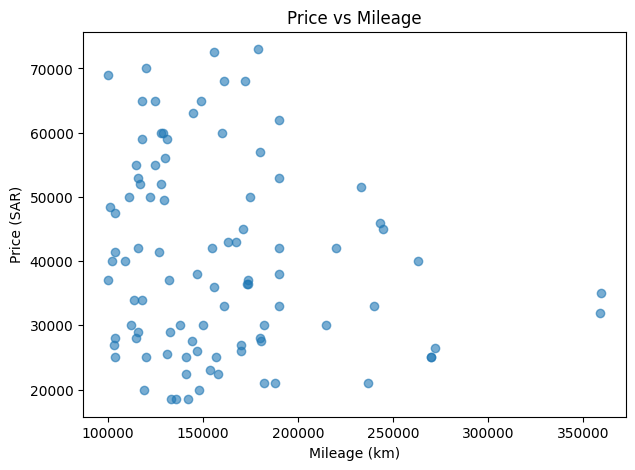

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(kia_df['Mileage'], kia_df['Price'], alpha=0.6)
plt.xlabel('Mileage (km)')
plt.ylabel('Price (SAR)')
plt.title('Price vs Mileage')
plt.show()

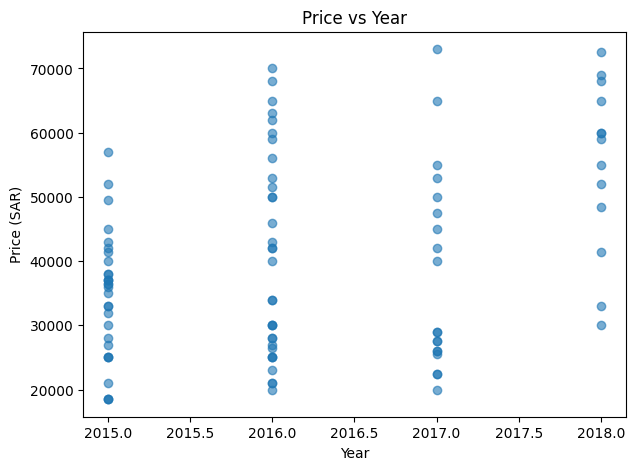

In [12]:
plt.figure(figsize=(7, 5))
plt.scatter(kia_df['Year'], kia_df['Price'], alpha=0.6)
plt.xlabel('Year')
plt.ylabel('Price (SAR)')
plt.title('Price vs Year')
plt.show()

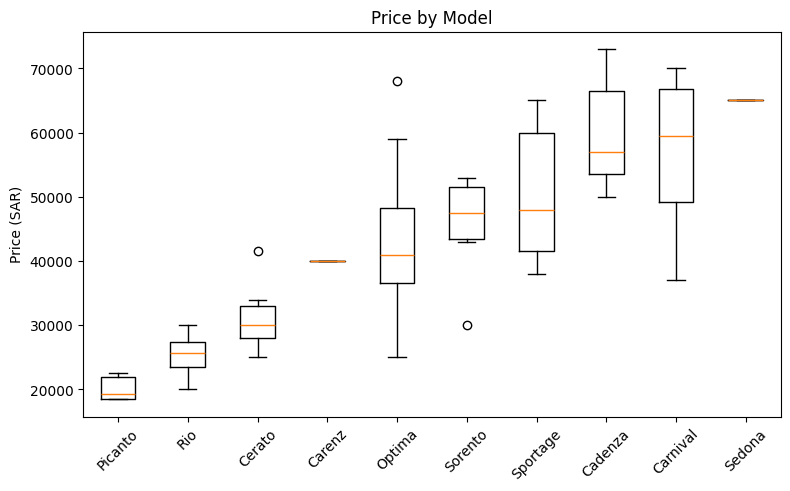

In [13]:
order = kia_df.groupby('Type')['Price'].median().sort_values().index
data = [kia_df.loc[kia_df['Type'] == t, 'Price'] for t in order]

plt.figure(figsize=(9, 5))
plt.boxplot(data)
plt.xticks(range(1, len(order) + 1), order, rotation=45)
plt.ylabel('Price (SAR)')
plt.title('Price by Model')
plt.show()

In [14]:
print(kia_df['Type'].value_counts())

Type
Optima      22
Rio         18
Cerato      14
Cadenza     11
Sportage    10
Picanto      6
Carnival     6
Sorento      6
Carenz       1
Sedona       1
Name: count, dtype: int64
